# MaskStitch — end-to-end pipeline walkthrough

**Solar Filament Segmentation Challenge 2026.** This notebook runs the adopted solution from
raw H-$\alpha$ observation to the submitted CSV, showing each stage and the reasoning behind it.

Adopted configuration: a YOLO11 instance-segmentation detector at native $2048^2$ proposes
filaments; each proposal is cropped, padded and letterboxed to $256^2$; an edge-attention U-Net
refines the mask; predictions are averaged over four flips when that preserves the mask's
topology; and the crop masks are stitched into a non-overlapping instance map by greedy
**mask-level** non-maximum suppression. Detection threshold 0.25, mask threshold 0.5.

**Prerequisites.** `pip install -r requirements.txt && pip install -e .`, the MAGFiLO data under
`FILAMENT_DATA_ROOT`, and trained weights under `FILAMENT_WORK_DIR` (`filament prepare`,
`filament train-yolo --seg`, `filament train-unet` — see the README). Section 8 regenerates the
submission from those weights.

In [1]:
import numpy as np, pandas as pd, torch, matplotlib.pyplot as plt
from ultralytics import YOLO

from solar_filaments.config import CropConfig, Paths, UNetConfig, YoloConfig
from solar_filaments.data.coco import (Dataset, load_image, load_split,
                                       merge_annotator_records, polygon_to_mask)
from solar_filaments.detectors import YoloSegDetector
from solar_filaments.inference import refine_candidates
from solar_filaments.models.refiner import load_refiner

CONF, MASK_THRES, NMS = 0.25, 0.5, 0.15          # the adopted operating point
paths = Paths()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
plt.rcParams.update({"figure.dpi": 110, "font.size": 9})
print("device:", device, "| data:", paths.data_root)

/home/marchezi/.local/lib/python3.12/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


device: cuda | data: /data/marchezi/filament_segmentation_2026/MAGFiLO_1.0_Kaggle_2026


## 1. The data, and why the split is not obvious

MAGFiLO gives 1154 *annotation records* over 707 *physical images*: up to three experts may
annotate the same photograph, each producing a record with its own identifier but a shared
`file_name`. Splitting on record identifiers would put the same photograph on both sides of the
split, so every split here is performed at the level of the photograph.

In [2]:
dataset = Dataset(paths.train_ann_path)
files = {im["file_name"] for im in dataset.images_by_id.values()}
multi = [f for f in files if len(dataset.file_name_to_image_ids[f]) > 1]
print(f"{len(dataset.images_by_id)} records over {len(files)} photographs; "
      f"{len(multi)} ({len(multi)/len(files):.0%}) carry more than one annotator")

train_ids, val_ids = load_split(paths.split_path)
f = lambda ids: {dataset.images_by_id[i]["file_name"] for i in ids}
print(f"train {len(f(train_ids))} photographs | val {len(f(val_ids))} | "
      f"overlap {len(f(train_ids) & f(val_ids))}")

1154 records over 707 photographs; 296 (42%) carry more than one annotator
train 672 photographs | val 35 | overlap 0


### How much do the experts agree?

This sets the scale for everything that follows. Clustering annotations across annotators of the
same photograph by the evaluation metric's own rule (mask IoU > 0.5), a third of distinct
filaments are marked by a minority of the available experts.

In [3]:
import collections
sup = collections.Counter(round(c["support"], 2)
                          for fn in sorted(multi)
                          for c in merge_annotator_records(dataset, fn, "union"))
n = sum(sup.values())
for k in sorted(sup):
    print(f"  marked by {k:.0%} of annotators: {sup[k]:5d}  ({sup[k]/n:5.1%})")
print(f"\n{n} clustered filaments over {len(multi)} multi-annotator photographs")

  marked by 33% of annotators:  1039  (31.9%)
  marked by 50% of annotators:   869  (26.7%)
  marked by 67% of annotators:   394  (12.1%)
  marked by 100% of annotators:   952  (29.3%)

3254 clustered filaments over 296 multi-annotator photographs


## 2. Preprocessing: the polygon rasterization convention

Before any modelling, an evaluation detail that changed our reported metric by more than any
model change. Ground-truth polygons must be rasterized to masks, and `cv2.fillPoly` disagrees
systematically with `pycocotools`, which is what the metric uses. The disagreement is a boundary
effect, so it is worst exactly on thin structures.

In [4]:
import cv2
def cv2_mask(seg, h, w):
    m = np.zeros((h, w), np.uint8)
    cv2.fillPoly(m, [np.asarray(seg, np.float64).reshape(-1, 2).round().astype(np.int32)], 1)
    return m.astype(bool)

ious, areas = [], []
for img_id in list(dataset.images_by_id)[:120]:
    info = dataset.images_by_id[img_id]
    for a in dataset.anns_by_image.get(img_id, []):
        A = polygon_to_mask(a["segmentation"], info["height"], info["width"]).astype(bool)
        B = cv2_mask(a["segmentation"], info["height"], info["width"])
        u = (A | B).sum()
        if u: ious.append((A & B).sum() / u); areas.append(int(A.sum()))
ious, areas = np.array(ious), np.array(areas)
med = np.median(areas)
print(f"n={len(ious)}  mean IoU between the two rasterizations: {ious.mean():.3f}")
print(f"  filaments below median area: {ious[areas < med].mean():.3f}")
print(f"  above median               : {ious[areas >= med].mean():.3f}")
print("\n-> polygon_to_mask uses pycocotools, matching the evaluator.")

n=808  mean IoU between the two rasterizations: 0.880
  filaments below median area: 0.858
  above median               : 0.902

-> polygon_to_mask uses pycocotools, matching the evaluator.


## 3. Detect

The detector proposes filaments on the full disk at native resolution. We keep its coarse masks
only to locate each proposal; the mask itself is produced by the refiner in the next stage.

20110511063154Uh.jpeg: (2048, 2048) -> 5 proposals at conf >= 0.25


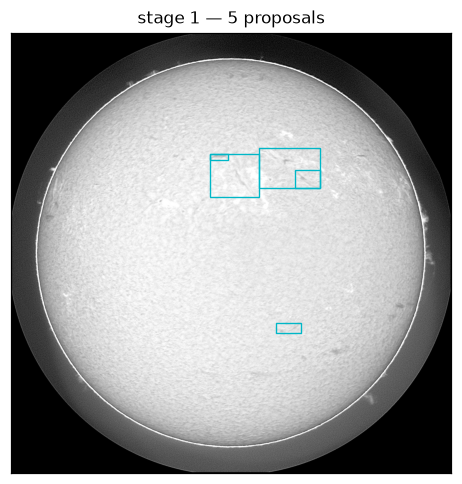

In [5]:
val_files = sorted({dataset.images_by_id[i]["file_name"] for i in val_ids})
fn = val_files[0]
img = load_image(paths.train_img_dir / fn)

detector = YoloSegDetector(
    YOLO(str(paths.runs_dir / f"{YoloConfig().name}_seg" / "weights" / "best.pt")),
    conf_thres=CONF, iou_thres=0.5, imgsz=2048)
cands = detector.detect(img)
print(f"{fn}: {img.shape} -> {len(cands)} proposals at conf >= {CONF}")

fig, ax = plt.subplots(figsize=(5.2, 5.2))
ax.imshow(img, cmap="gray", vmin=np.percentile(img, 1), vmax=np.percentile(img, 99))
for c in cands:
    x1, y1, x2, y2 = c.tight_box()
    ax.add_patch(plt.Rectangle((x1, y1), x2-x1, y2-y1, fill=False, ec="#00b7c7", lw=0.9))
ax.set_xticks([]); ax.set_yticks([]); ax.set_title(f"stage 1 — {len(cands)} proposals")
plt.show()

## 4. Crop and refine

Each proposal is padded by a factor of 1.35 and letterbox-resized to $256^2$. Aspect-ratio
preservation matters: filaments are long and thin, and a naive square crop spends most of its
resolution on empty margin. The refiner is a compact U-Net with an edge-guided attention
bottleneck; its prediction is averaged over four flips, and the average is accepted only when it
preserves the single-view mask's topology.

refiner: 8.82M parameters


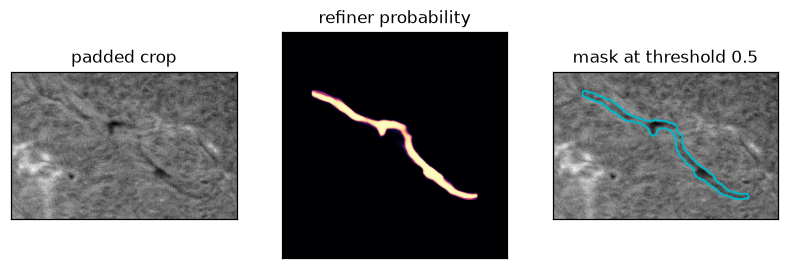

In [6]:
from solar_filaments.inference import padded_rect_crop, _segment_maybe_tta, undo_letterbox
ccfg = CropConfig()
unet = load_refiner(paths.ckpt_dir / "unet_best.pt", device,
                    use_edge_attention=UNetConfig().use_edge_attention)
print(f"refiner: {sum(p.numel() for p in unet.parameters())/1e6:.2f}M parameters")

c = max(cands, key=lambda c: (c.tight_box()[2]-c.tight_box()[0]) * (c.tight_box()[3]-c.tight_box()[1]))
x1b, y1b, x2b, y2b = c.tight_box()
cx1, cy1, cx2, cy2 = padded_rect_crop(x1b, y1b, x2b-x1b, y2b-y1b, img.shape[1], img.shape[0],
                                      ccfg.pad_factor, ccfg.min_crop_side)
crop = img[cy1:cy2, cx1:cx2]
mask_lb, prob, scale, left, top = _segment_maybe_tta(unet, device, crop, ccfg.crop_size,
                                                     MASK_THRES, True)
mask = undo_letterbox(mask_lb, scale, left, top, cx2-cx1, cy2-cy1) > 0

fig, ax = plt.subplots(1, 3, figsize=(9, 3))
ax[0].imshow(crop, cmap="gray"); ax[0].set_title("padded crop")
ax[1].imshow(prob, cmap="magma"); ax[1].set_title("refiner probability")
ax[2].imshow(crop, cmap="gray"); ax[2].contour(mask, [0.5], colors="#00b7c7", linewidths=1.2)
ax[2].set_title(f"mask at threshold {MASK_THRES}")
for a in ax: a.set_xticks([]); a.set_yticks([])
plt.show()

## 5. Stitch

Crop masks are pasted back at full resolution and merged into a non-overlapping instance map.
Suppression is done in **mask** space, not box space: box IoU is a poor identity criterion for
long, thin, diagonal structures, and duplicate detections routinely survive it. A candidate
already mostly claimed by a higher-confidence instance is rejected rather than admitted as a
fragment.

5 proposals -> 3 instances after mask-level NMS


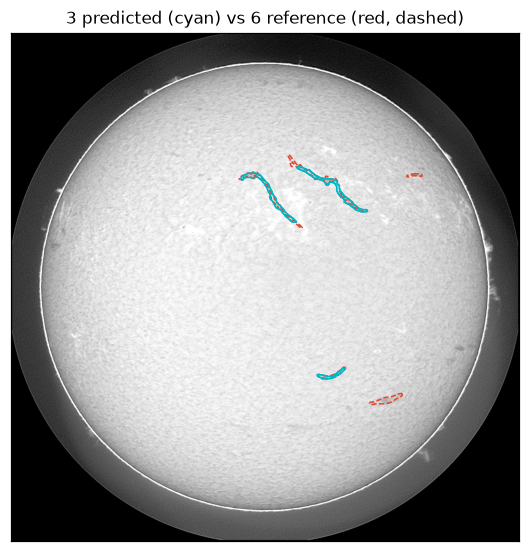

In [7]:
label_map, scores = refine_candidates(
    img, cands, unet, device, crop_size=ccfg.crop_size, pad_factor=ccfg.pad_factor,
    min_crop_side=ccfg.min_crop_side, mask_thresh=MASK_THRES,
    min_instance_area=25, mask_nms_thresh=NMS, use_tta=True)
n_inst = int(label_map.max())
print(f"{len(cands)} proposals -> {n_inst} instances after mask-level NMS")

info = dataset.images_by_id[dataset.file_name_to_image_ids[fn][0]]
gt = [polygon_to_mask(a["segmentation"], info["height"], info["width"]).astype(bool)
      for a in dataset.anns_by_image[dataset.file_name_to_image_ids[fn][0]]]
fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(img, cmap="gray", vmin=np.percentile(img, 1), vmax=np.percentile(img, 99))
for g in gt: ax.contour(g, [0.5], colors="#e24a33", linewidths=1.0, linestyles="dashed")
for i in range(1, n_inst+1): ax.contour(label_map == i, [0.5], colors="#00b7c7", linewidths=1.1)
ax.set_xticks([]); ax.set_yticks([])
ax.set_title(f"{n_inst} predicted (cyan) vs {len(gt)} reference (red, dashed)")
plt.show()

## 6. Evaluate

Panoptic Quality, pooled globally rather than averaged per image, using the organizers' own
scoring logic. We report the factorization $\mathrm{PQ} = \mathrm{SQ}\times\mathrm{RQ}$ because
the two move independently: SQ is mask quality on what we matched, RQ is the detection term.

In [8]:
from solar_filaments.eval.self_eval import format_summary, get_overlap_df, summarize_overlap
from solar_filaments.rle import encode_rle_counts
COLS = ["filament_id", "segmentation_rle"]

gt_rows = []
for img_id in val_ids:
    inf = dataset.images_by_id[img_id]
    for k, a in enumerate(dataset.anns_by_image.get(img_id, []), 1):
        m = polygon_to_mask(a["segmentation"], inf["height"], inf["width"]).astype(bool)
        if m.any():
            gt_rows.append({"filament_id": f"{img_id}_{k}", "segmentation_rle": encode_rle_counts(m)})

pred_rows = []
for f_ in val_files:
    im = load_image(paths.train_img_dir / f_)
    lm, _ = refine_candidates(im, detector.detect(im), unet, device, crop_size=ccfg.crop_size,
        pad_factor=ccfg.pad_factor, min_crop_side=ccfg.min_crop_side, mask_thresh=MASK_THRES,
        min_instance_area=25, mask_nms_thresh=NMS, use_tta=True)
    stem = f_.rsplit(".", 1)[0]
    pred_rows += [{"filament_id": f"{stem}_{i}", "segmentation_rle": encode_rle_counts(lm == i)}
                  for i in range(1, int(lm.max())+1) if (lm == i).any()]

s = summarize_overlap(get_overlap_df(pd.DataFrame(gt_rows, columns=COLS),
                                     pd.DataFrame(pred_rows, columns=COLS)))
print(format_summary(s))

PQ=0.4571  (SQ=0.674 x RQ=0.678)  TP=222 FP=94 FN=117  GT miss=22.1%  pred FP=18.4%  fragmented=0.6%  over-merged=2.2%


### Context: what does this number mean?

Two experts annotating the same filament agree at a mean IoU of 0.631. Our SQ against held-out
annotations is 0.665 — the masks already match the reference about as closely as a second expert
does, so mask quality is not where the remaining loss lives. The loss is in recognition, and
specifically in detection: of the reference filaments we fail to match, 56% receive no
overlapping proposal at all, and they are systematically the small and faint ones.

## 7. What we varied, and what it returned

Ten axes, evaluated in isolation on this same split. Only the last row cleared the measured
noise floor of $\pm0.009$.

In [9]:
pd.set_option("display.max_colwidth", 60)
pd.DataFrame([
 ("detector architecture", "9M @1024 vs 27.6M @2048", "equivalent within noise"),
 ("annotator-merge target", "single / majority / union", "equivalent within noise"),
 ("refiner capacity", "8.8M vs ResNet18 15.4M", "+0.009 crop Dice, +0.000 PQ"),
 ("crop context (pad factor)", "1.35 / 1.60 / 1.80, each retrained", "null; 0.08 PQ trap if mismatched"),
 ("learned re-scorer", "10 features, AUC 0.845 vs 0.777", "same operating point"),
 ("extra proposal source", "full-disk semantic segmenter", "recall up, PQ down"),
 ("self-training", "2500 unlabelled archive images", "null at best; recall collapse if sparse"),
 ("oriented boxes", "YOLO11-obb", "better separation, worse recall"),
 ("photometric normalization", "limb flattening + CLAHE", "below baseline"),
 ("joint threshold retuning", "conf x mask threshold, together", "+0.014 PQ  <-- the only gain"),
], columns=["axis", "what changed", "result"])

,axis,what changed,result
0,detector architecture,9M @1024 vs 27.6M @2048,equivalent within noise
1,annotator-merge target,single / majority / union,equivalent within noise
2,refiner capacity,8.8M vs ResNet18 15.4M,"+0.009 crop Dice, +0.000 PQ"
3,crop context (pad factor),"1.35 / 1.60 / 1.80, each retrained",null; 0.08 PQ trap if mismatched
4,learned re-scorer,"10 features, AUC 0.845 vs 0.777",same operating point
5,extra proposal source,full-disk semantic segmenter,"recall up, PQ down"
6,self-training,2500 unlabelled archive images,null at best; recall collapse if sparse
7,oriented boxes,YOLO11-obb,"better separation, worse recall"
8,photometric normalization,limb flattening + CLAHE,below baseline
9,joint threshold retuning,"conf x mask threshold, together",+0.014 PQ <-- the only gain


## 8. Generate the submission

The same pipeline over the 180 test images. This is the file that was submitted.

In [10]:
from pathlib import Path
test_paths = sorted(paths.test_img_dir.glob("*.jpeg"))
rows = []
for p in test_paths:
    im = load_image(p)
    lm, _ = refine_candidates(im, detector.detect(im), unet, device, crop_size=ccfg.crop_size,
        pad_factor=ccfg.pad_factor, min_crop_side=ccfg.min_crop_side, mask_thresh=MASK_THRES,
        min_instance_area=25, mask_nms_thresh=NMS, use_tta=True)
    rows += [{"filament_id": f"{p.stem}_{i}", "segmentation_rle": encode_rle_counts(lm == i)}
             for i in range(1, int(lm.max())+1) if (lm == i).any()]

sub = pd.DataFrame(rows, columns=COLS)
out = Path(paths.work_dir) / "submission_from_notebook.csv"
sub.to_csv(out, index=False)
covered = sub.filament_id.str.rsplit("_", n=1).str[0].nunique()
print(f"{len(sub)} instances over {covered}/{len(test_paths)} test images -> {out}")
print(f"unique ids: {sub.filament_id.is_unique}")
sub.head()

1270 instances over 178/180 test images -> /home/marchezi/python_projects/solar_filaments_detection/work/submission_from_notebook.csv
unique ids: True


,filament_id,segmentation_rle
0,20110120105534Ch_1,``Pi23lo13N1N1010000_OKWQN6fn1K[QN4dn1N[QN1fn1OZQN1gn1OX...
1,20110120105534Ch_2,WjPQ21no12O0O1O1O1O1O1N1000O1000O0010O01000000K5O1I8N01O...
2,20110130110334Ch_1,h_Te27fo15N5K1O10OlPN@hn1b0SQNCln1>PQNDQo1e01O1O3N0010N6...
3,20110214175414Mh_1,a^fd23lo11O2O1O00001O1O010O0O10O10O1O10O100001O000000000...
4,20110214175414Mh_2,iY_g24io19I9H0O1O2O0O010NO2NO12O11OO11M111O0001O0O100M3O...
